In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
df = pd.read_csv("MBP_DATA.csv")

In [ ]:
df.head()

,Id,machineRPM,machineVibration,needleRuntime,dateTime,machineSerialNumber,status,machineVoltageMean,machineVoltageMin,machineVoltageMax,machineCurrentMean,machineCurrentMin,machineCurrentMax,machinePowerMean,machinePowerMin,machinePowerMax,epochT,identify
0,1.0,0.0,"10,243,20,1345,30,508,40,14100,50,624,60,380,7...",2091.0,56:33.1,2L1KE00310,Running,228.141098,227.887878,228.577652,1.703543,0.439162,2.274957,388.648159,100.079748,520.004262,1.783055e+09,Healthy
1,2.0,0.0,"10,372,20,1199,30,954,40,12617,50,1085,60,339,...",2021.0,56:51.0,2L1KE00310,Running,227.880783,227.023895,228.822220,1.738606,0.414957,2.274699,396.195000,94.205185,520.501668,1.783055e+09,Healthy
2,3.0,0.0,"10,163,20,1737,30,790,40,14648,50,819,60,382,7...",1701.0,57:31.6,2L1KE00310,Running,229.731049,229.299240,231.106674,1.958960,0.603197,2.235570,450.034030,138.312650,516.655192,1.783055e+09,Healthy
3,4.0,0.0,"10,281,20,1663,30,902,40,14581,50,920,60,417,7...",2076.0,58:48.4,2L1KE00310,Running,231.092712,230.839767,231.638061,1.664485,0.510704,2.222093,384.650266,117.890733,514.721284,1.783055e+09,Healthy
4,5.0,0.0,"10,267,20,1444,30,564,40,14485,50,675,60,320,7...",2084.0,00:28.9,2L1KE00310,Running,230.475372,229.171844,231.269638,1.635873,0.455371,2.241769,377.028512,104.358121,518.453178,1.783055e+09,Healthy


In [ ]:
columns_to_drop = ['Id', 'epochT', 'dateTime', 'machineSerialNumber', 'Remarks', 'status', 'machineRPM']

In [ ]:
df = df.drop(columns=[col for col in columns_to_drop if col in df.columns], errors='ignore')

In [ ]:
df.head()

,machineVibration,needleRuntime,machineVoltageMean,machineVoltageMin,machineVoltageMax,machineCurrentMean,machineCurrentMin,machineCurrentMax,machinePowerMean,machinePowerMin,machinePowerMax,identify
0,"10,243,20,1345,30,508,40,14100,50,624,60,380,7...",2091.0,228.141098,227.887878,228.577652,1.703543,0.439162,2.274957,388.648159,100.079748,520.004262,Healthy
1,"10,372,20,1199,30,954,40,12617,50,1085,60,339,...",2021.0,227.880783,227.023895,228.822220,1.738606,0.414957,2.274699,396.195000,94.205185,520.501668,Healthy
2,"10,163,20,1737,30,790,40,14648,50,819,60,382,7...",1701.0,229.731049,229.299240,231.106674,1.958960,0.603197,2.235570,450.034030,138.312650,516.655192,Healthy
3,"10,281,20,1663,30,902,40,14581,50,920,60,417,7...",2076.0,231.092712,230.839767,231.638061,1.664485,0.510704,2.222093,384.650266,117.890733,514.721284,Healthy
4,"10,267,20,1444,30,564,40,14485,50,675,60,320,7...",2084.0,230.475372,229.171844,231.269638,1.635873,0.455371,2.241769,377.028512,104.358121,518.453178,Healthy


In [ ]:
print('Original DataFrame columns:')
print(df.columns.tolist())

# Optional: Clean column names by stripping whitespace
df.columns = df.columns.str.strip()
print('\nDataFrame columns after stripping whitespace:')
print(df.columns.tolist())

# Re-run the drop command with potentially cleaned column names
df = df.drop(columns=[col for col in columns_to_drop if col in df.columns], errors='ignore')

print('\nDataFrame head after attempting to drop columns again:')
display(df.head())

Original DataFrame columns:
['machineVibration', 'needleRuntime', 'machineVoltageMean', 'machineVoltageMin', 'machineVoltageMax', 'machineCurrentMean', 'machineCurrentMin', 'machineCurrentMax', 'machinePowerMean', 'machinePowerMin', 'machinePowerMax', 'identify']

DataFrame columns after stripping whitespace:
['machineVibration', 'needleRuntime', 'machineVoltageMean', 'machineVoltageMin', 'machineVoltageMax', 'machineCurrentMean', 'machineCurrentMin', 'machineCurrentMax', 'machinePowerMean', 'machinePowerMin', 'machinePowerMax', 'identify']

DataFrame head after attempting to drop columns again:


,machineVibration,needleRuntime,machineVoltageMean,machineVoltageMin,machineVoltageMax,machineCurrentMean,machineCurrentMin,machineCurrentMax,machinePowerMean,machinePowerMin,machinePowerMax,identify
0,"10,243,20,1345,30,508,40,14100,50,624,60,380,7...",2091.0,228.141098,227.887878,228.577652,1.703543,0.439162,2.274957,388.648159,100.079748,520.004262,Healthy
1,"10,372,20,1199,30,954,40,12617,50,1085,60,339,...",2021.0,227.880783,227.023895,228.822220,1.738606,0.414957,2.274699,396.195000,94.205185,520.501668,Healthy
2,"10,163,20,1737,30,790,40,14648,50,819,60,382,7...",1701.0,229.731049,229.299240,231.106674,1.958960,0.603197,2.235570,450.034030,138.312650,516.655192,Healthy
3,"10,281,20,1663,30,902,40,14581,50,920,60,417,7...",2076.0,231.092712,230.839767,231.638061,1.664485,0.510704,2.222093,384.650266,117.890733,514.721284,Healthy
4,"10,267,20,1444,30,564,40,14485,50,675,60,320,7...",2084.0,230.475372,229.171844,231.269638,1.635873,0.455371,2.241769,377.028512,104.358121,518.453178,Healthy


In [ ]:
df.head()

,machineVibration,needleRuntime,machineVoltageMean,machineVoltageMin,machineVoltageMax,machineCurrentMean,machineCurrentMin,machineCurrentMax,machinePowerMean,machinePowerMin,machinePowerMax,identify
0,"10,243,20,1345,30,508,40,14100,50,624,60,380,7...",2091.0,228.141098,227.887878,228.577652,1.703543,0.439162,2.274957,388.648159,100.079748,520.004262,Healthy
1,"10,372,20,1199,30,954,40,12617,50,1085,60,339,...",2021.0,227.880783,227.023895,228.822220,1.738606,0.414957,2.274699,396.195000,94.205185,520.501668,Healthy
2,"10,163,20,1737,30,790,40,14648,50,819,60,382,7...",1701.0,229.731049,229.299240,231.106674,1.958960,0.603197,2.235570,450.034030,138.312650,516.655192,Healthy
3,"10,281,20,1663,30,902,40,14581,50,920,60,417,7...",2076.0,231.092712,230.839767,231.638061,1.664485,0.510704,2.222093,384.650266,117.890733,514.721284,Healthy
4,"10,267,20,1444,30,564,40,14485,50,675,60,320,7...",2084.0,230.475372,229.171844,231.269638,1.635873,0.455371,2.241769,377.028512,104.358121,518.453178,Healthy


In [ ]:

vib_cols = [f"vib_{hz}Hz" for hz in range(10, 610, 10)]
MAX_VIBRATION_INDEX = len(vib_cols)  # Exactly 60


def parse_all_vibration(vibration_str):
    """Extracts all 60 vibration amplitudes from your database string format."""
    if pd.isna(vibration_str) or not isinstance(vibration_str, str):
        return [0.0] * MAX_VIBRATION_INDEX

    try:

        all_numbers = [
            float(x.strip()) for x in vibration_str.split(",") if x.strip()
        ]

        amplitudes = all_numbers[1::2]

        return (amplitudes + [0.0] * MAX_VIBRATION_INDEX)[:MAX_VIBRATION_INDEX]
    except Exception:
        return [0.0] * MAX_VIBRATION_INDEX

In [ ]:
file_path = "MBP_DATA.csv"

In [ ]:
df.head()

,machineVibration,needleRuntime,machineVoltageMean,machineVoltageMin,machineVoltageMax,machineCurrentMean,machineCurrentMin,machineCurrentMax,machinePowerMean,machinePowerMin,machinePowerMax,identify
0,"10,243,20,1345,30,508,40,14100,50,624,60,380,7...",2091.0,228.141098,227.887878,228.577652,1.703543,0.439162,2.274957,388.648159,100.079748,520.004262,Healthy
1,"10,372,20,1199,30,954,40,12617,50,1085,60,339,...",2021.0,227.880783,227.023895,228.822220,1.738606,0.414957,2.274699,396.195000,94.205185,520.501668,Healthy
2,"10,163,20,1737,30,790,40,14648,50,819,60,382,7...",1701.0,229.731049,229.299240,231.106674,1.958960,0.603197,2.235570,450.034030,138.312650,516.655192,Healthy
3,"10,281,20,1663,30,902,40,14581,50,920,60,417,7...",2076.0,231.092712,230.839767,231.638061,1.664485,0.510704,2.222093,384.650266,117.890733,514.721284,Healthy
4,"10,267,20,1444,30,564,40,14485,50,675,60,320,7...",2084.0,230.475372,229.171844,231.269638,1.635873,0.455371,2.241769,377.028512,104.358121,518.453178,Healthy


In [ ]:
try:
    df_raw = pd.read_csv(file_path)
    print(f" Successfully imported {len(df_raw)} rows from '{file_path}'!")
except FileNotFoundError:
    print(
        f" ERROR: File '{file_path}' not found! Make sure it is uploaded to your environment."
    )
    exit()

 Successfully imported 2377 rows from 'MBP_DATA.csv'!


In [ ]:
print("Extracting 60 vibration spectrum features...")
parsed_vibrations = (
    df_raw["machineVibration"].apply(parse_all_vibration).tolist()
)
df_vib_extracted = pd.DataFrame(parsed_vibrations, columns=vib_cols)

Extracting 60 vibration spectrum features...


In [ ]:
numerical_features = [
    "machineRPM",
    "needleRuntime",
    "machineVoltageMean",
    "machineVoltageMin",
    "machineVoltageMax",
    "machineCurrentMean",
    "machineCurrentMin",
    "machineCurrentMax",
    "machinePowerMean",
    "machinePowerMin",
    "machinePowerMax",
]

In [ ]:

df_features = pd.concat([df_raw[numerical_features], df_vib_extracted], axis=1)


df_features = df_features.fillna(df_features.mean())

In [ ]:
print("Scaling data to normalize features...")
scaler = StandardScaler()
scaled_matrix = scaler.fit_transform(df_features)

Scaling data to normalize features...


In [ ]:
print("Dividing operational profiles into 3 distinct clusters...")
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_raw["cluster_label"] = kmeans.fit_predict(scaled_matrix)

Dividing operational profiles into 3 distinct clusters...


In [ ]:
metadata_cols = ["Id", "dateTime", "machineSerialNumber", "status"]
df_final_display = pd.concat(
    [df_raw[metadata_cols + ["cluster_label"]], df_features], axis=1
)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

print("\n=== CLUSTERING DONE! SHOWING PROCESSED DATASET ===")
print(df_final_display.head())


output_file = "MBP_Clustered_Final_Data.csv"
df_final_display.to_csv(output_file, index=False)
print(
    f"\n💾 Saved all data with cluster tags successfully to '{output_file}'!"
)


=== CLUSTERING DONE! SHOWING PROCESSED DATASET ===
    Id dateTime machineSerialNumber   status  cluster_label  machineRPM  needleRuntime  machineVoltageMean  machineVoltageMin  machineVoltageMax  machineCurrentMean  machineCurrentMin  machineCurrentMax  machinePowerMean  machinePowerMin  machinePowerMax  vib_10Hz  vib_20Hz  vib_30Hz  vib_40Hz  vib_50Hz  vib_60Hz  vib_70Hz  vib_80Hz  vib_90Hz  vib_100Hz  vib_110Hz  vib_120Hz  vib_130Hz  vib_140Hz  vib_150Hz  vib_160Hz  vib_170Hz  vib_180Hz  vib_190Hz  vib_200Hz  vib_210Hz  vib_220Hz  vib_230Hz  vib_240Hz  vib_250Hz  vib_260Hz  vib_270Hz  vib_280Hz  vib_290Hz  vib_300Hz  vib_310Hz  vib_320Hz  vib_330Hz  vib_340Hz  vib_350Hz  vib_360Hz  vib_370Hz  vib_380Hz  vib_390Hz  vib_400Hz  vib_410Hz  vib_420Hz  vib_430Hz  vib_440Hz  vib_450Hz  vib_460Hz  vib_470Hz  vib_480Hz  vib_490Hz  vib_500Hz  vib_510Hz  vib_520Hz  vib_530Hz  vib_540Hz  vib_550Hz  vib_560Hz  vib_570Hz  vib_580Hz  vib_590Hz  vib_600Hz
0  1.0  56:33.1          2L1KE00310  Runni

In [ ]:
from google.colab import files

output_file = "MBP_Clustered_Final_Data.csv"
print(f"Downloading '{output_file}'...")
files.download(output_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Example: How `machineVibration` string becomes multiple columns

Let's take a sample `machineVibration` string and see how the `parse_vibration_data` function turns it into a dictionary that will then become new columns.

In [ ]:

all_numeric_feature_cols = numerical_features + vib_cols


cluster_profiles = df_final_display[
    ['cluster_label'] + all_numeric_feature_cols
].groupby('cluster_label').mean()

print(cluster_profiles)

               machineRPM  needleRuntime  machineVoltageMean  machineVoltageMin  machineVoltageMax  machineCurrentMean  machineCurrentMin  machineCurrentMax  machinePowerMean  machinePowerMin  machinePowerMax    vib_10Hz     vib_20Hz    vib_30Hz      vib_40Hz    vib_50Hz    vib_60Hz    vib_70Hz    vib_80Hz     vib_90Hz   vib_100Hz   vib_110Hz   vib_120Hz    vib_130Hz   vib_140Hz   vib_150Hz   vib_160Hz   vib_170Hz   vib_180Hz   vib_190Hz   vib_200Hz   vib_210Hz   vib_220Hz   vib_230Hz   vib_240Hz   vib_250Hz   vib_260Hz   vib_270Hz   vib_280Hz   vib_290Hz   vib_300Hz   vib_310Hz   vib_320Hz   vib_330Hz   vib_340Hz   vib_350Hz   vib_360Hz   vib_370Hz   vib_380Hz   vib_390Hz   vib_400Hz   vib_410Hz   vib_420Hz   vib_430Hz   vib_440Hz   vib_450Hz   vib_460Hz   vib_470Hz   vib_480Hz   vib_490Hz   vib_500Hz   vib_510Hz   vib_520Hz   vib_530Hz   vib_540Hz   vib_550Hz   vib_560Hz   vib_570Hz   vib_580Hz   vib_590Hz   vib_600Hz
cluster_label                                                     

In [ ]:
import pandas as pd


overlap_table = pd.crosstab(
    df_final_display['status'],
    df_final_display['cluster_label']
)

print("--- Cluster Overlap Grid ---")
print(overlap_table)


--- Cluster Overlap Grid ---
cluster_label     0    1    2
status                       
Running        1305  951  113


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns


cluster_mapping = {
    0: 'Warning',
    1: 'Failure',
    2: 'Healthy'
}

## Testing Clusters with New Data

First, let's load your 'real data'. Please ensure the new CSV file has a similar structure to the original data.

In [ ]:
df_final_display['mapped_cluster_name'] = df_final_display['cluster_label'].map(cluster_mapping)

In [ ]:
y_true = df_final_display['status']
y_pred = df_final_display['mapped_cluster_name']

In [ ]:
labels_order = ['Healthy', 'Warning', 'Failure']


temp_combined = pd.DataFrame({
    'true_labels': df_raw['identify'], # Use the correct 'true' status column
    'pred_labels': df_final_display['mapped_cluster_name'] # This should be correctly mapped cluster names
})
temp_combined.dropna(inplace=True)

y_true_clean = temp_combined['true_labels'].astype(str)
y_pred_clean = temp_combined['pred_labels'].astype(str)

cm = confusion_matrix(y_true_clean, y_pred_clean, labels=labels_order)

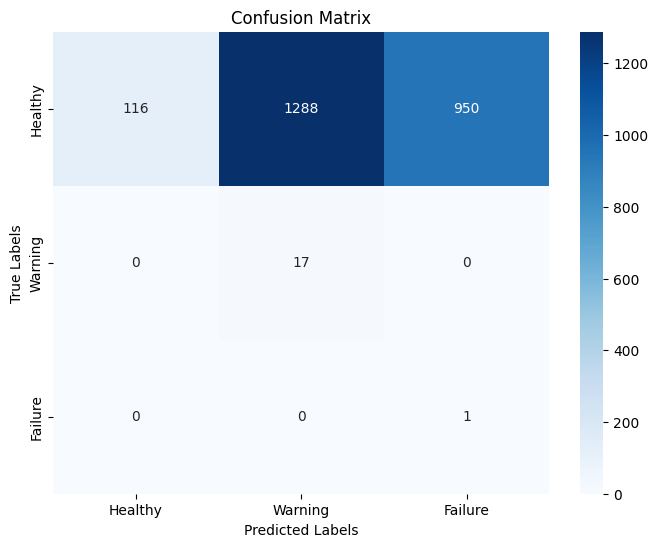

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels_order, yticklabels=labels_order)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
print("Dataset Shape:", df.shape)

Dataset Shape: (2377, 12)


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2377 entries, 0 to 2376
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   machineVibration    2354 non-null   object 
 1   needleRuntime       2369 non-null   float64
 2   machineVoltageMean  2369 non-null   float64
 3   machineVoltageMin   2369 non-null   float64
 4   machineVoltageMax   2369 non-null   float64
 5   machineCurrentMean  2369 non-null   float64
 6   machineCurrentMin   2369 non-null   float64
 7   machineCurrentMax   2369 non-null   float64
 8   machinePowerMean    2369 non-null   float64
 9   machinePowerMin     2369 non-null   float64
 10  machinePowerMax     2369 non-null   float64
 11  identify            2372 non-null   object 
dtypes: float64(10), object(2)
memory usage: 223.0+ KB
None


Now, we need to apply the same preprocessing steps to the `new_df` as we did to the original data. This includes dropping specific columns, cleaning the `machineVibration` column, and handling missing values.

Next, we will scale the preprocessed new data using the same `StandardScaler` fitted on the original training data. This ensures that the new data is transformed consistently with the data the K-Means model was trained on.

Finally, we apply the trained K-Means model to predict cluster labels for your new data.

To understand the characteristics of the clusters in your new data, we can calculate the mean values of the features for each predicted cluster, similar to what we did for the original data.

### Exporting DataFrames with Cluster Labels

You can now find these CSV files in your Colab environment's file browser or download them directly.

### Calculating Confusion Matrix and Classification Report (Requires True Labels)

This section demonstrates how to use `confusion_matrix` and `classification_report`. You need two arrays:
*   `y_true`: The actual, known labels for your data.
*   `y_pred`: The predicted labels (e.g., your K-means `cluster_label` after potentially mapping them to match `y_true`).

**For K-means, if you have 'ground truth' labels, you would typically align your cluster labels (`cluster_label`) with these true labels to make this comparison meaningful.**

In [ ]:
# Please input your confusion matrix code here.

In [ ]:
# Please input your confusion matrix code here.